In [1]:
# ============================================================
# TRAVELTIDE – USERS INSPECTION
# ============================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import shutil
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Define project directories
PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

SOURCE_FILE = (
    PROJECT_DIR
    / "data"
    / "working"
    / "01_exploration"
    / "expl_users.csv"
)

CLEANING_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "02_inspection"
)

TARGET_FILE = CLEANING_DIR / "insp_users.csv"

# 3. Create cleaning directory
CLEANING_DIR.mkdir(parents=True, exist_ok=True)

# 4. Check source file
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(
        f"Source file not found: {SOURCE_FILE}"
    )

# 5. Create cleaning copy
shutil.copy2(SOURCE_FILE, TARGET_FILE)

# 6. Load cleaning copy into DataFrame
users = pd.read_csv(TARGET_FILE)

# 7. Display loading report
print("=" * 60)
print("TRAVELTIDE – USERS INSPECTION")
print("=" * 60)

print(f"Source:  {SOURCE_FILE}")
print(f"Target:  {TARGET_FILE}")
print(f"Rows:    {users.shape[0]:,}")
print(f"Columns: {users.shape[1]}")
print("Status:  SUCCESS")
print("=" * 60)


TRAVELTIDE – USERS INSPECTION
Source:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\01_exploration\expl_users.csv
Target:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_users.csv
Rows:    1,020,926
Columns: 11
Status:  SUCCESS


In [2]:
# Allgemeine Informationen zum Datensatz
users.info()

# Statistische Zusammenfassung aller Spalten
display(users.describe(include="all").T)

# Anzahl fehlender Werte je Spalte
display(users.isnull().sum().to_frame("Missing Values"))
print("****")
type(users.isnull().sum().to_frame("Missing Values"))

# Anzahl doppelter Zeilen
print("Duplicate rows:", users.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1020926 entries, 0 to 1020925
Data columns (total 11 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   user_id           1020926 non-null  int64  
 1   birthdate         1020926 non-null  str    
 2   gender            1020926 non-null  str    
 3   married           1020926 non-null  str    
 4   has_children      1020926 non-null  str    
 5   home_country      1020926 non-null  str    
 6   home_city         1020926 non-null  str    
 7   home_airport      1020926 non-null  str    
 8   home_airport_lat  1020926 non-null  float64
 9   home_airport_lon  1020926 non-null  float64
 10  sign_up_date      1020926 non-null  str    
dtypes: float64(2), int64(1), str(8)
memory usage: 85.7 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,1020926.0,NaN,NaN,NaN,510462.5,294716.094799,0.0,255231.25,510462.5,765693.75,1020925.0
birthdate,1020926,22581,2006-09-03,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1020926,3,M,558986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
married,1020926,2,f,626109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_children,1020926,2,f,701289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_country,1020926,2,usa,848354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_city,1020926,105,new york,121290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_airport,1020926,159,JFK,60711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_airport_lat,1020926.0,NaN,NaN,NaN,38.553523,6.120248,21.316,33.942,39.297,42.276,61.251
home_airport_lon,1020926.0,NaN,NaN,NaN,-93.920357,18.096452,-157.927,-112.008,-89.977,-77.456,-63.499


,Missing Values
user_id,0
birthdate,0
gender,0
married,0
has_children,0
home_country,0
home_city,0
home_airport,0
home_airport_lat,0
home_airport_lon,0


****
Duplicate rows: 0


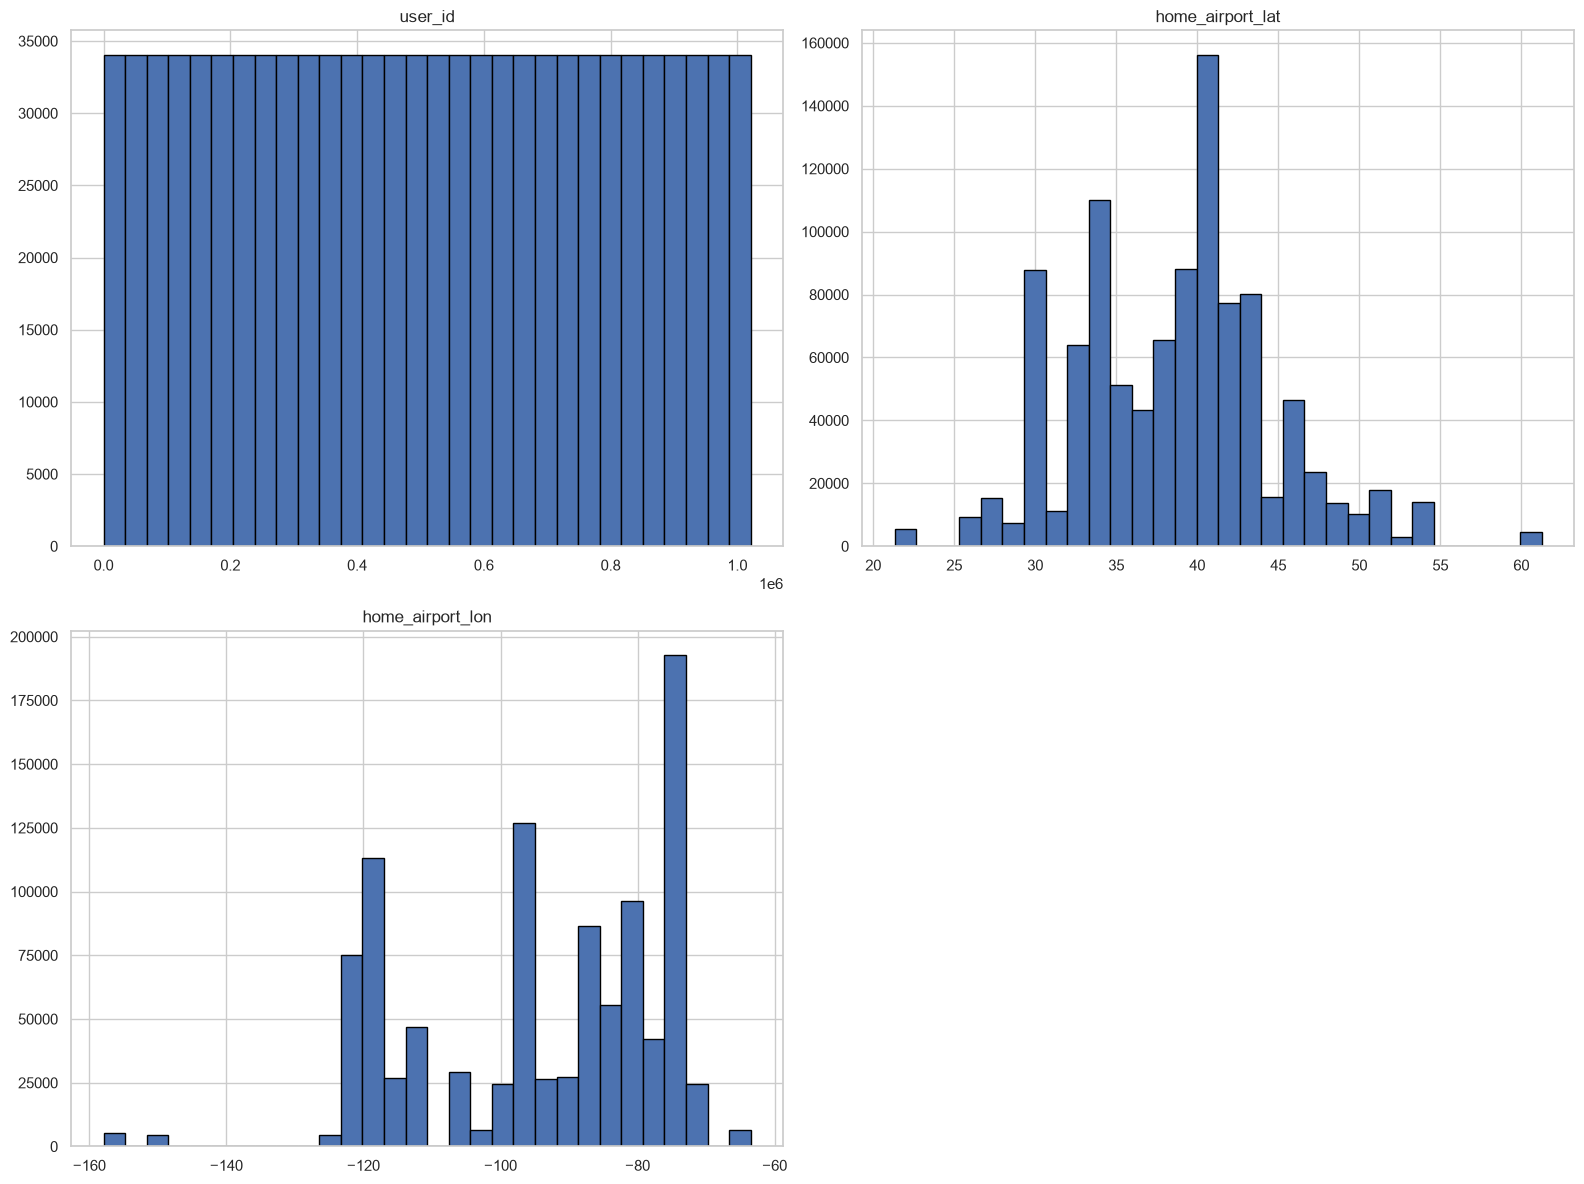

In [3]:
# Verteilung numerischer Variablen
users.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()


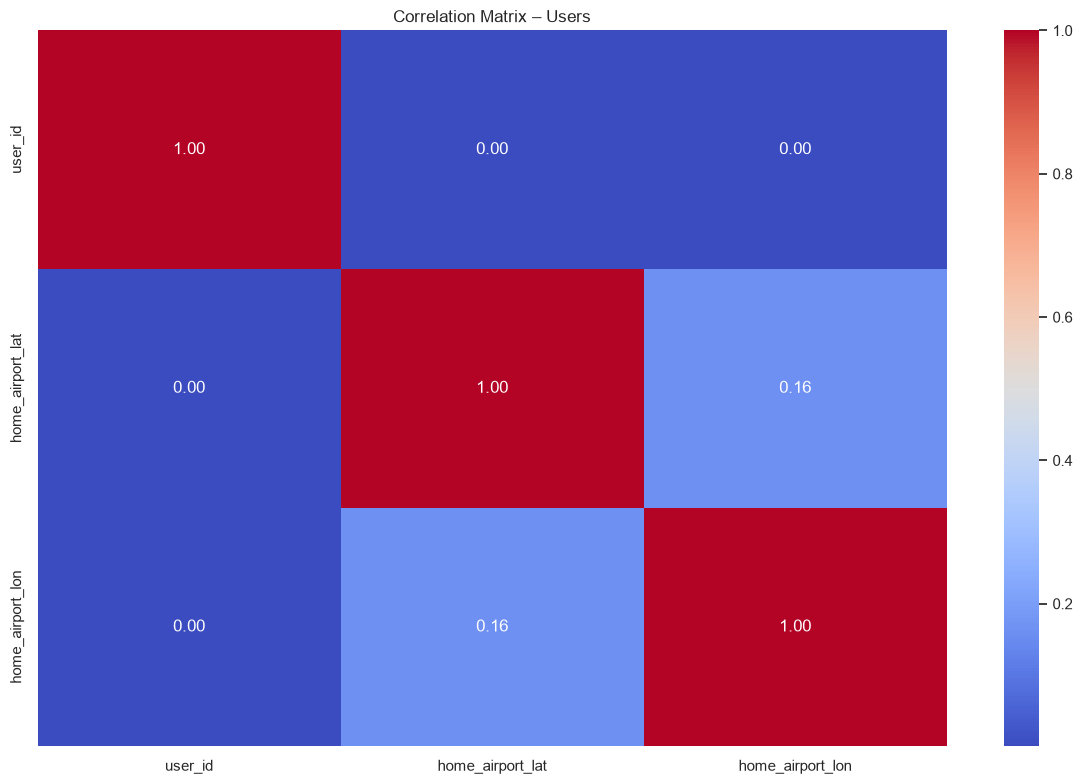

In [4]:
# ============================================================
# TRAVELTIDE – USERS: CORRELATION MATRIX
# ============================================================

# Nur numerische Spalten berücksichtigen
numeric_users = users.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_users.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix – Users")
plt.tight_layout()
plt.show()


In [5]:
# ============================================================
# TRAVELTIDE – USERS: BOOLEAN CONVERSION
# ============================================================

# 1. Define columns to check and convert
boolean_columns = [
    "married",
    "has_children"
]

# 2. Check whether all required columns exist
missing_columns = [
    col for col in boolean_columns
    if col not in users.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in users: {missing_columns}"
    )

# 3. Check for NaN values
missing_values = users[boolean_columns].isna().sum()

print("Missing values before conversion:")
print(missing_values)

# 4. Convert only if no NaN values are present
if missing_values.sum() == 0:

    for col in boolean_columns:
        values = users[col].astype("string").str.strip().str.lower()

        unexpected = values[~values.isin(["f", "t"])]

        if not unexpected.empty:
            raise ValueError(
                f"Unexpected values in column '{col}': "
                f"{unexpected.unique().tolist()}"
            )

        users[col] = values.map({
            "f": False,
            "t": True
        })

    print("\nBoolean conversion successful.")

    # 5. Save cleaned dataset
    users.to_csv(TARGET_FILE, index=False)

    print(f"\nSaved successfully to:\n{TARGET_FILE}")

else:
    print(
        "\nConversion cancelled: NaN values were found. "
        "Please investigate them first."
    )


Missing values before conversion:
married         0
has_children    0
dtype: int64

Boolean conversion successful.

Saved successfully to:
D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_users.csv


In [6]:
# Check resulting data types and values
boolean_counts = pd.DataFrame({
    "True": (users[boolean_columns] == True).sum(),
    "False": (users[boolean_columns] == False).sum()
})

display(boolean_counts)

,True,False
married,394817,626109
has_children,319637,701289
